<a href="https://colab.research.google.com/github/lakshuu-jay/Projects/blob/main/AirlinePassengerSatisfactionPrediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

   Unnamed: 0      id  Gender      Customer Type  Age   Type of Travel  \
0           0   70172    Male     Loyal Customer   13  Personal Travel   
1           1    5047    Male  disloyal Customer   25  Business travel   
2           2  110028  Female     Loyal Customer   26  Business travel   
3           3   24026  Female     Loyal Customer   25  Business travel   
4           4  119299    Male     Loyal Customer   61  Business travel   

      Class  Flight Distance  Inflight wifi service  \
0  Eco Plus              460                      3   
1  Business              235                      3   
2  Business             1142                      2   
3  Business              562                      2   
4  Business              214                      3   

   Departure/Arrival time convenient  ...  Inflight entertainment  \
0                                  4  ...                       5   
1                                  2  ...                       1   
2                

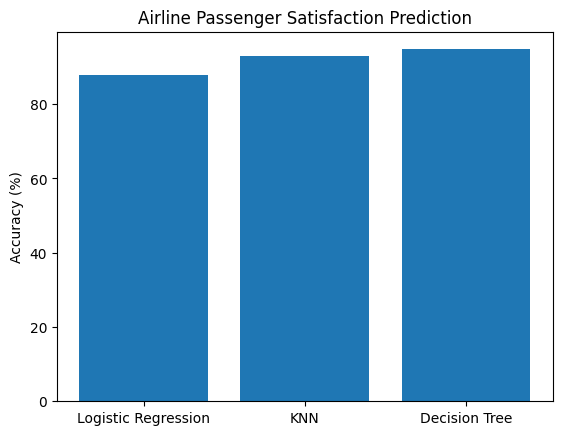


Conclusion:
The model with the highest accuracy performs best on the test dataset.

Comment on the dataset:
The dataset contains passenger details, flight information, service ratings, and satisfaction labels. Machine learning classifiers can use these features to predict passenger satisfaction.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

df = pd.read_csv("Airline Data.csv")

print(df.head())
print(df.info())
print(df.isnull().sum())

df = df.drop(columns=["Unnamed: 0", "id"], errors="ignore")
df = df.drop_duplicates()

df["Arrival Delay in Minutes"] = df["Arrival Delay in Minutes"].fillna(
    df["Arrival Delay in Minutes"].median()
)

for col in df.select_dtypes(include="object").columns:
    if col != "satisfaction":
        df[col] = LabelEncoder().fit_transform(df[col])

df["satisfaction"] = LabelEncoder().fit_transform(df["satisfaction"])

X = df.drop("satisfaction", axis=1)
y = df["satisfaction"]

X = X.fillna(X.median())

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(random_state=42)
}

accuracies = []

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred) * 100
    accuracies.append(accuracy)
    print(name, "Accuracy:", round(accuracy, 2), "%")

plt.bar(models.keys(), accuracies)
plt.ylabel("Accuracy (%)")
plt.title("Airline Passenger Satisfaction Prediction")
plt.show()

print("\nConclusion:")
print("The model with the highest accuracy performs best on the test dataset.")

print("\nComment on the dataset:")
print("The dataset contains passenger details, flight information, service ratings, and satisfaction labels. Machine learning classifiers can use these features to predict passenger satisfaction.")